In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

df = pd.read_excel("Online Retail.xlsx")

# Feature engineering
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

print("Dataset shape:", df.shape)
print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df.head()

Dataset shape: (541909, 9)

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
Revenue               float64
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0
dtype: int64

Duplicate rows: 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [4]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDataset information:")
df.info()

Number of rows: 541909
Number of columns: 9

Column names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Data types:
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
Revenue               float64
dtype: object

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
Revenue             0
dtype: int64

Duplicate rows: 5268

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object   

In [7]:
from pathlib import Path

OUTPUT_DIR = Path("outputs")
CHART_DIR = OUTPUT_DIR / "charts"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

print("Output folders created successfully!")

quality_report = pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_count": df.isnull().sum(),
    "missing_percentage": (df.isnull().mean() * 100).round(2),
    "unique_values": df.nunique()
})

quality_report.to_csv(
    OUTPUT_DIR / "data_quality_report.csv",
    index=True
)

quality_report

Output folders created successfully!


,data_type,missing_count,missing_percentage,unique_values
InvoiceNo,object,0,0.00,25900
StockCode,object,0,0.00,4070
Description,object,1454,0.27,4223
Quantity,int64,0,0.00,722
InvoiceDate,datetime64[ns],0,0.00,23260
UnitPrice,float64,0,0.00,1630
CustomerID,float64,135080,24.93,4372
Country,object,0,0.00,38
Revenue,float64,0,0.00,6204


In [8]:
numeric_df = df.select_dtypes(include="number")

summary = numeric_df.describe().T

summary["median"] = numeric_df.median()
summary["variance"] = numeric_df.var()
summary["skewness"] = numeric_df.skew()

summary = summary.round(2)

summary.to_csv(
    OUTPUT_DIR / "summary_statistics.csv"
)

summary

,count,mean,std,min,25%,50%,75%,max,median,variance,skewness
Quantity,541909.0,9.55,218.08,-80995.00,1.00,3.00,10.00,80995.0,3.00,47559.39,-0.26
UnitPrice,541909.0,4.61,96.76,-11062.06,1.25,2.08,4.13,38970.0,2.08,9362.47,186.51
CustomerID,406829.0,15287.69,1713.60,12346.00,13953.00,15152.00,16791.00,18287.0,15152.00,2936426.00,0.03
Revenue,541909.0,17.99,378.81,-168469.60,3.40,9.75,17.40,168469.6,9.75,143497.64,-0.96


In [9]:
# Create a copy so the original dataset remains unchanged
df_clean = df.copy()

# 1. Remove duplicate rows
duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()

# 2. Remove rows where essential values are missing
df_clean = df_clean.dropna(subset=["InvoiceNo", "StockCode", "Quantity", "UnitPrice"])

# 3. Convert InvoiceDate to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"], errors="coerce"
)

# 4. Convert numeric columns to numeric types
df_clean["Quantity"] = pd.to_numeric(
    df_clean["Quantity"], errors="coerce"
)
df_clean["UnitPrice"] = pd.to_numeric(
    df_clean["UnitPrice"], errors="coerce"
)

# 5. Remove rows with invalid dates or missing numeric values
df_clean = df_clean.dropna(
    subset=["InvoiceDate", "Quantity", "UnitPrice"]
)

# 6. Create a revenue column
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

# Display cleaning results
print("Original rows:", len(df))
print("Duplicate rows removed:", duplicates_before)
print("Cleaned rows:", len(df_clean))
print("Remaining missing values:")
print(df_clean.isnull().sum())

# Save the cleaned dataset
df_clean.to_csv(OUTPUT_DIR / "cleaned_online_retail.csv", index=False)

print("\nCleaned dataset saved successfully!")
df_clean.head()

Original rows: 541909
Duplicate rows removed: 5268
Cleaned rows: 536641
Remaining missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
Revenue             0
dtype: int64

Cleaned dataset saved successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


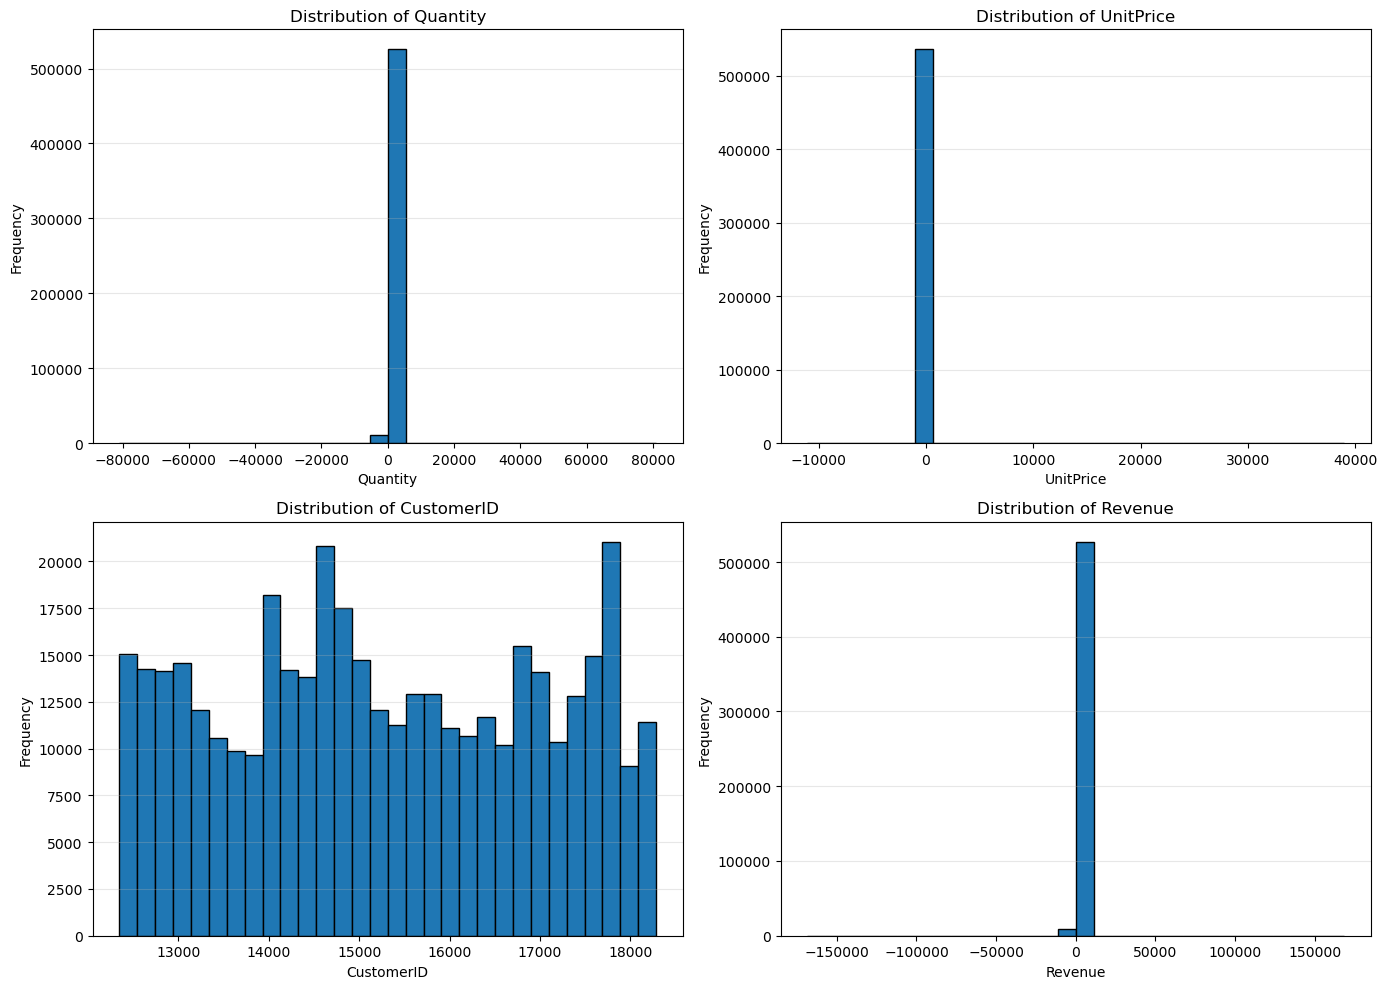

Numeric distribution charts saved successfully!


In [10]:
import matplotlib.pyplot as plt
import math

# Select all numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Calculate subplot layout
n_cols = 2
n_rows = math.ceil(len(numeric_cols) / n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(14, 5 * n_rows)
)

# Convert axes into a flat list
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Create a histogram for each numeric column
for i, col in enumerate(numeric_cols):
    axes[i].hist(
        df_clean[col].dropna(),
        bins=30,
        edgecolor="black"
    )
    axes[i].set_title(f"Distribution of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")
    axes[i].grid(axis="y", alpha=0.3)

# Remove unused subplot spaces
for j in range(len(numeric_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()

# Save the figure
plt.savefig(
    CHART_DIR / "numeric_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Numeric distribution charts saved successfully!")

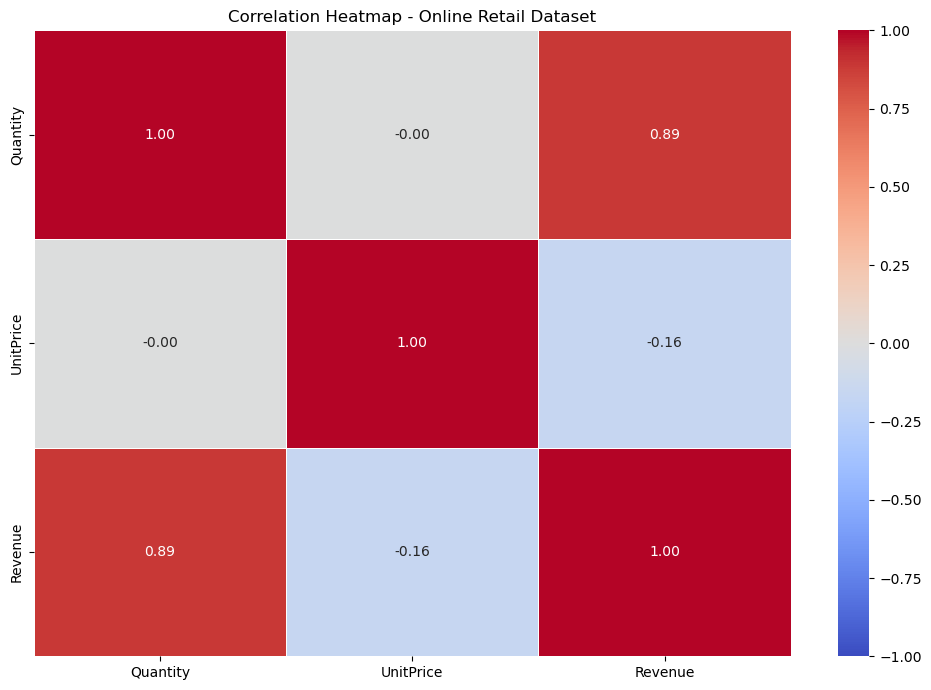

Correlation heatmap saved successfully!


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns
numeric_df = df_clean.select_dtypes(include="number")

# Remove identifier columns that do not represent measurable quantities
identifier_cols = ["CustomerID"]
numeric_df = numeric_df.drop(
    columns=[col for col in identifier_cols if col in numeric_df.columns],
    errors="ignore"
)

# Calculate the correlation matrix
correlation_matrix = numeric_df.corr()

# Plot the heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Online Retail Dataset")
plt.tight_layout()

# Save the chart
plt.savefig(
    CHART_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully!")

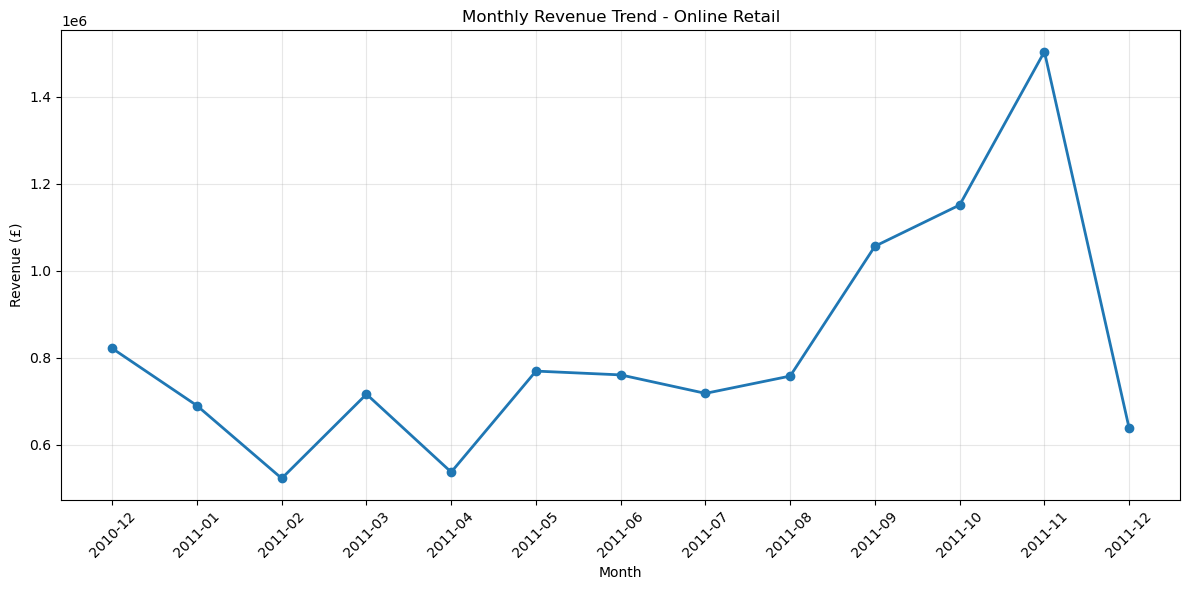

Highest revenue month:
2011-11 — £ 1503866.78
Monthly revenue analysis saved successfully!


In [12]:
# Extract year and month from the invoice date
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

# Exclude returns and cancellations from the sales analysis
sales_df = df_clean[
    (df_clean["Quantity"] > 0) &
    (df_clean["UnitPrice"] > 0) &
    (~df_clean["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

# Calculate monthly revenue
monthly_revenue = (
    sales_df.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Convert period values to strings for plotting
monthly_revenue.index = monthly_revenue.index.astype(str)

# Plot monthly revenue
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_revenue.index,
    monthly_revenue.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend - Online Retail")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save chart
plt.savefig(
    CHART_DIR / "monthly_revenue_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the highest-revenue month
print("Highest revenue month:")
print(monthly_revenue.idxmax(), "— £", round(monthly_revenue.max(), 2))

# Save monthly revenue data
monthly_revenue.to_csv(OUTPUT_DIR / "monthly_revenue.csv")

print("Monthly revenue analysis saved successfully!")

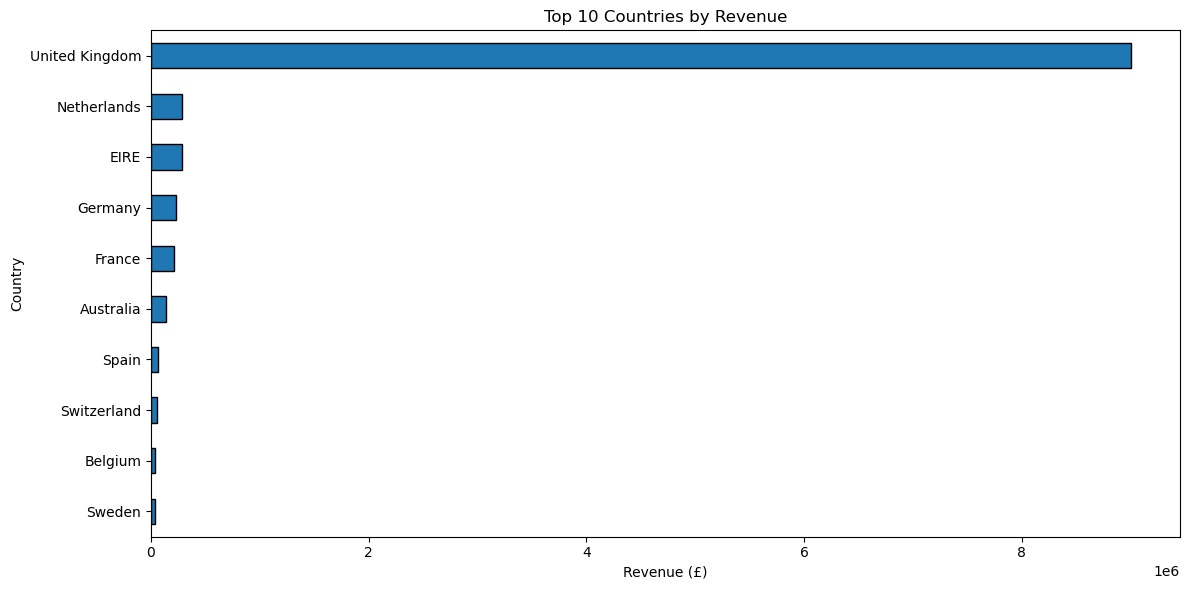

,Revenue (£)
Country,
United Kingdom,9001744.09
Netherlands,285446.34
EIRE,283140.52
Germany,228678.40
France,209625.37
Australia,138453.81
Spain,61558.56
Switzerland,57067.60
Belgium,41196.34


Country-wise revenue analysis saved successfully!


In [13]:
# Calculate revenue by country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 countries
top_10_countries = country_revenue.head(10)

# Plot the results
plt.figure(figsize=(12, 6))

top_10_countries.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

# Save the chart
plt.savefig(
    CHART_DIR / "top_10_countries_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the revenue values
display(top_10_countries.to_frame(name="Revenue (£)").round(2))

# Save the results
top_10_countries.to_csv(
    OUTPUT_DIR / "top_10_countries_revenue.csv"
)

print("Country-wise revenue analysis saved successfully!")


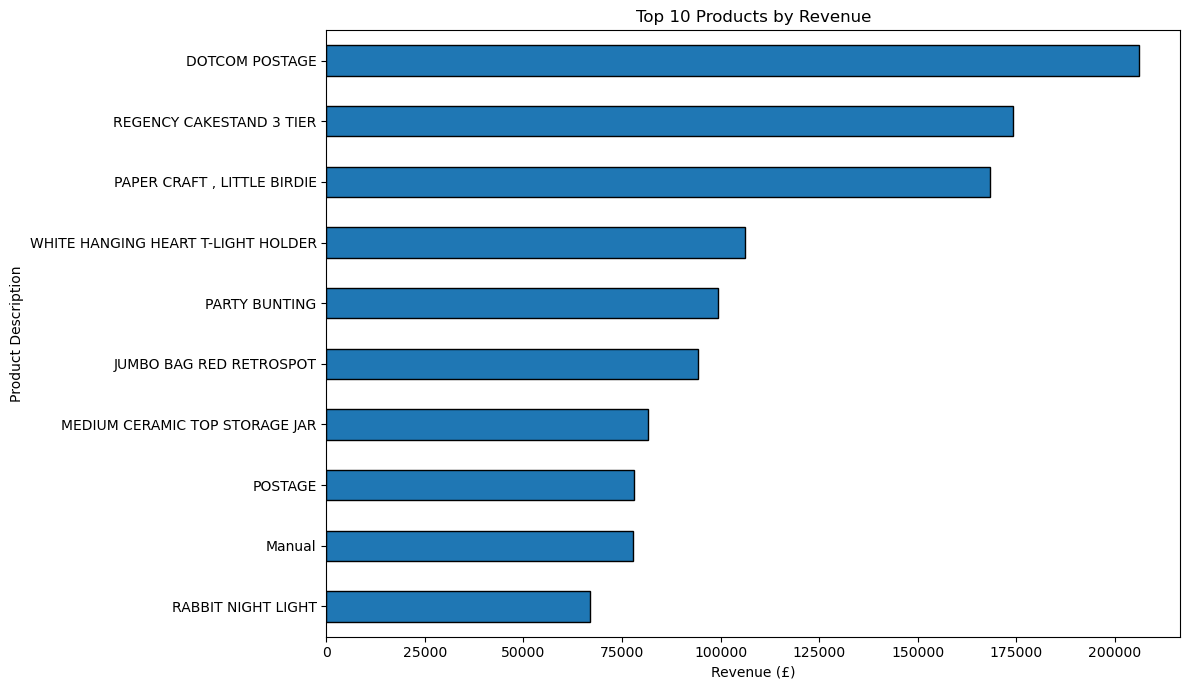

,Revenue (£)
Description,
DOTCOM POSTAGE,206248.77
REGENCY CAKESTAND 3 TIER,174156.54
"PAPER CRAFT , LITTLE BIRDIE",168469.60
WHITE HANGING HEART T-LIGHT HOLDER,106236.72
PARTY BUNTING,99445.23
JUMBO BAG RED RETROSPOT,94159.81
MEDIUM CERAMIC TOP STORAGE JAR,81700.92
POSTAGE,78101.88
Manual,77752.82


Top 10 product analysis saved successfully!


In [14]:
# Group products by description and calculate total revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Select the top 10 products
top_10_products = product_revenue.head(10)

# Plot the results
plt.figure(figsize=(12, 7))

top_10_products.sort_values().plot(
    kind="barh",
    edgecolor="black"
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product Description")
plt.tight_layout()

# Save the chart
plt.savefig(
    CHART_DIR / "top_10_products_revenue.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display the top 10 products
display(
    top_10_products
    .rename("Revenue (£)")
    .to_frame()
    .round(2)
)

# Save the results
top_10_products.to_csv(
    OUTPUT_DIR / "top_10_products_revenue.csv"
)

print("Top 10 product analysis saved successfully!")

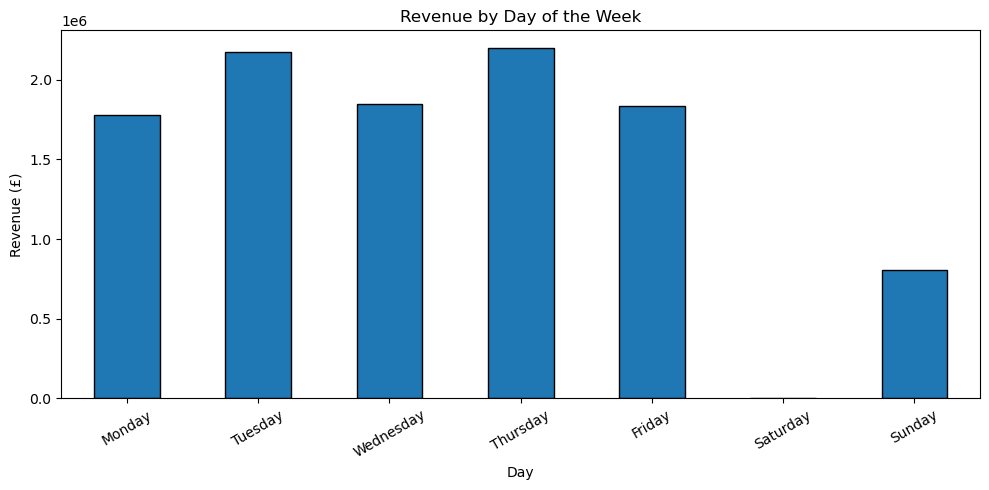

,Revenue (£)
DayOfWeek,
Monday,1775782.07
Tuesday,2175700.51
Wednesday,1847074.38
Thursday,2199292.57
Friday,1837470.49
Saturday,0.00
Sunday,806790.78


In [15]:
# Extract day of the week
sales_df["DayOfWeek"] = sales_df["InvoiceDate"].dt.day_name()

day_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

daily_sales = (
    sales_df.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(day_order, fill_value=0)
)

plt.figure(figsize=(10, 5))
daily_sales.plot(kind="bar", edgecolor="black")

plt.title("Revenue by Day of the Week")
plt.xlabel("Day")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=30)
plt.tight_layout()

plt.savefig(CHART_DIR / "revenue_by_day.png", dpi=300, bbox_inches="tight")
plt.show()

display(daily_sales.to_frame("Revenue (£)").round(2))
daily_sales.to_csv(OUTPUT_DIR / "revenue_by_day.csv")

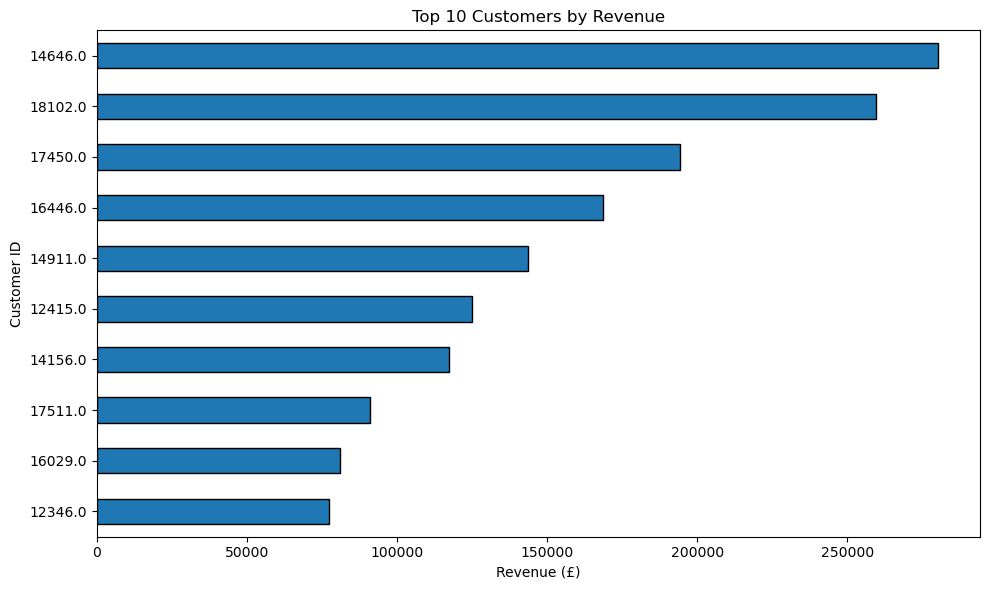

,Total_Revenue,Total_Orders,Total_Quantity
CustomerID,,,
14646.0,280206.02,73,196915
18102.0,259657.30,60,64124
17450.0,194390.79,46,69973
16446.0,168472.50,2,80997
14911.0,143711.17,201,80240
12415.0,124914.53,21,77374
14156.0,117210.08,55,57768
17511.0,91062.38,31,64549
16029.0,80850.84,63,40108


In [16]:
# CustomerID is required for customer-level analysis
if "CustomerID" in sales_df.columns:
    customer_sales = (
        sales_df.dropna(subset=["CustomerID"])
        .groupby("CustomerID")
        .agg(
            Total_Revenue=("Revenue", "sum"),
            Total_Orders=("InvoiceNo", "nunique"),
            Total_Quantity=("Quantity", "sum")
        )
        .sort_values("Total_Revenue", ascending=False)
    )

    top_customers = customer_sales.head(10)

    plt.figure(figsize=(10, 6))
    top_customers["Total_Revenue"].sort_values().plot(
        kind="barh", edgecolor="black"
    )
    plt.title("Top 10 Customers by Revenue")
    plt.xlabel("Revenue (£)")
    plt.ylabel("Customer ID")
    plt.tight_layout()

    plt.savefig(CHART_DIR / "top_10_customers.png", dpi=300, bbox_inches="tight")
    plt.show()

    display(top_customers.round(2))
    customer_sales.to_csv(OUTPUT_DIR / "customer_sales_analysis.csv")
else:
    print("CustomerID is not available in this dataset.")

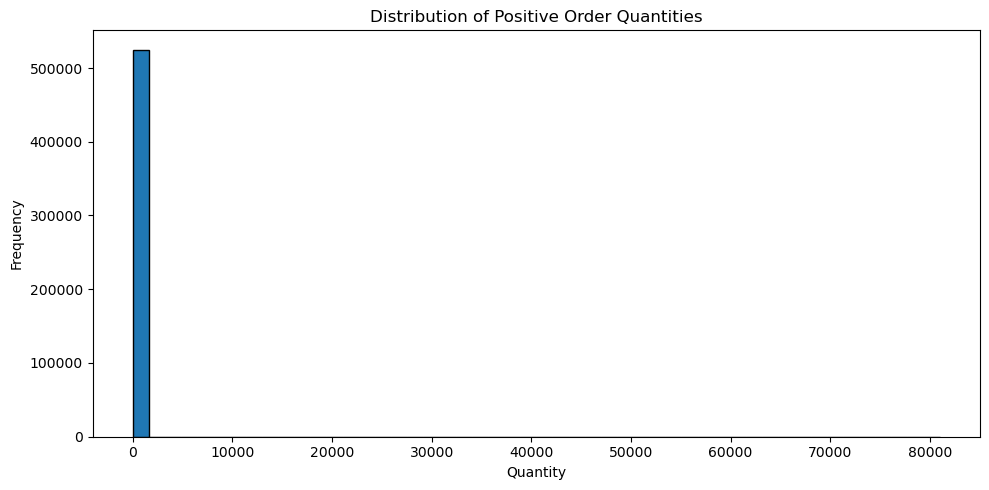

,Quantity Statistics
count,524878.00
mean,10.62
std,156.28
min,1.00
25%,1.00
50%,4.00
75%,11.00
max,80995.00


In [17]:
quantity_summary = sales_df["Quantity"].describe()

plt.figure(figsize=(10, 5))
plt.hist(sales_df["Quantity"], bins=50, edgecolor="black")

plt.title("Distribution of Positive Order Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(CHART_DIR / "order_quantity_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

display(quantity_summary.to_frame("Quantity Statistics").round(2))
quantity_summary.to_csv(OUTPUT_DIR / "quantity_summary.csv")

Unique cancellation invoice numbers: 3836
Rows with negative quantities: 10587
Total quantity returned (absolute): 482517
Absolute value of negative-quantity lines (£): 893979.73


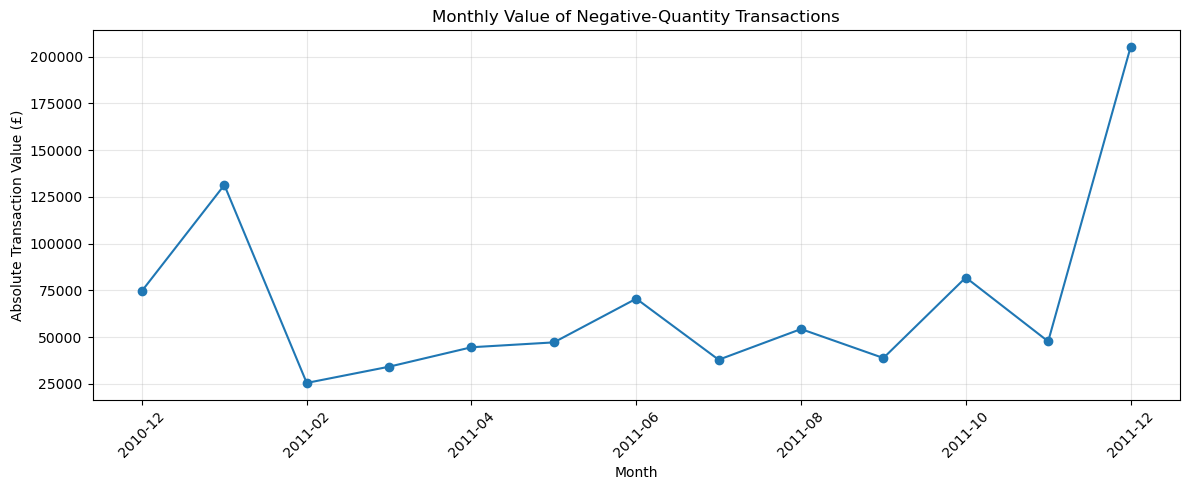

Returns and cancellation analysis completed.


In [18]:
# Identify cancellation invoices
invoice_numbers = df_clean["InvoiceNo"].astype(str)

cancellation_rows = df_clean[
    invoice_numbers.str.startswith("C")
].copy()

# Identify negative-quantity rows
returns_df = df_clean[df_clean["Quantity"] < 0].copy()

# Calculate summary metrics
cancellation_count = cancellation_rows["InvoiceNo"].nunique()
return_rows = len(returns_df)
return_quantity = returns_df["Quantity"].abs().sum()
return_value = returns_df["Revenue"].abs().sum()

print("Unique cancellation invoice numbers:", cancellation_count)
print("Rows with negative quantities:", return_rows)
print("Total quantity returned (absolute):", round(return_quantity, 2))
print("Absolute value of negative-quantity lines (£):", round(return_value, 2))

# Plot negative-quantity rows by month
if not returns_df.empty:
    returns_df["YearMonth"] = returns_df["InvoiceDate"].dt.to_period("M").astype(str)

    monthly_returns = (
        returns_df.groupby("YearMonth")["Revenue"]
        .apply(lambda x: x.abs().sum())
    )

    plt.figure(figsize=(12, 5))
    monthly_returns.plot(marker="o")

    plt.title("Monthly Value of Negative-Quantity Transactions")
    plt.xlabel("Month")
    plt.ylabel("Absolute Transaction Value (£)")
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()

    plt.savefig(CHART_DIR / "monthly_returns.png", dpi=300, bbox_inches="tight")
    plt.show()

    monthly_returns.to_csv(OUTPUT_DIR / "monthly_returns.csv")

print("Returns and cancellation analysis completed.")

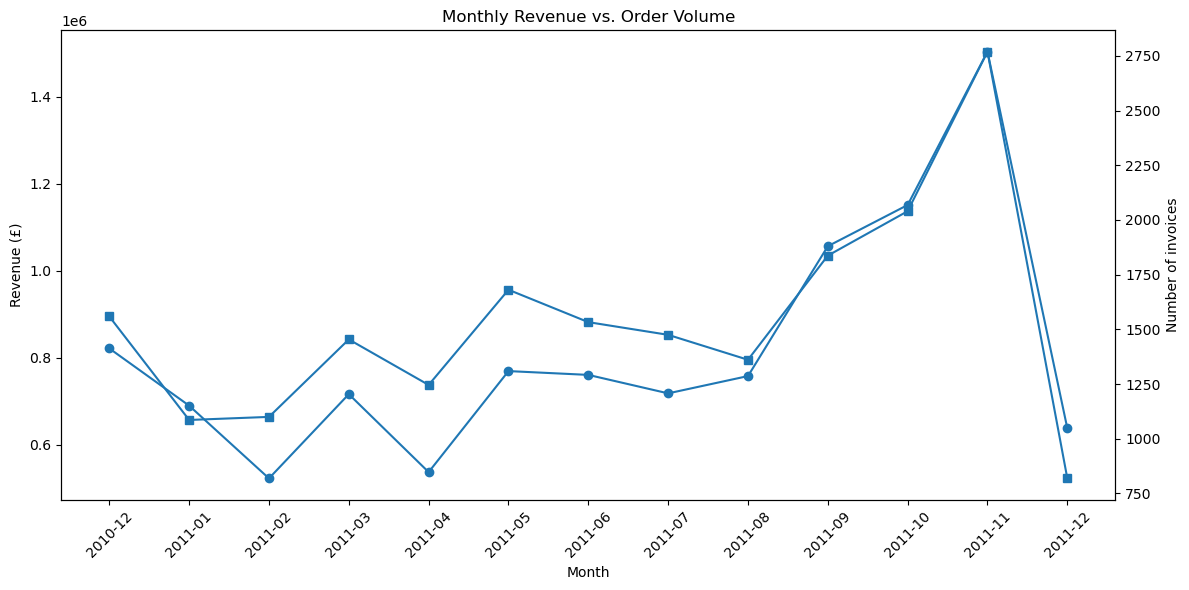

,Revenue,Unique_Invoices,Units_Sold
YearMonth,,,
2010-12,821452.73,1559,358019
2011-01,689811.61,1086,387099
2011-02,522545.56,1100,282934
2011-03,716215.26,1454,376599
2011-04,536968.49,1246,307953
2011-05,769296.61,1681,395001
2011-06,760547.01,1533,388511
2011-07,718076.12,1475,399693
2011-08,757841.38,1361,421020


In [19]:
monthly_performance = (
    sales_df.groupby("YearMonth")
    .agg(
        Revenue=("Revenue", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Units_Sold=("Quantity", "sum")
    )
    .sort_index()
)

monthly_performance.index = monthly_performance.index.astype(str)

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(
    monthly_performance.index,
    monthly_performance["Revenue"],
    marker="o",
    label="Revenue"
)
ax1.set_xlabel("Month")
ax1.set_ylabel("Revenue (£)")
ax1.tick_params(axis="x", rotation=45)

ax2 = ax1.twinx()
ax2.plot(
    monthly_performance.index,
    monthly_performance["Unique_Invoices"],
    marker="s",
    label="Unique invoices"
)
ax2.set_ylabel("Number of invoices")

plt.title("Monthly Revenue vs. Order Volume")
fig.tight_layout()

plt.savefig(CHART_DIR / "monthly_revenue_vs_orders.png", dpi=300, bbox_inches="tight")
plt.show()

display(monthly_performance.round(2))
monthly_performance.to_csv(OUTPUT_DIR / "monthly_performance.csv")

In [20]:
country_analysis = (
    sales_df.groupby("Country")
    .agg(
        Revenue=("Revenue", "sum"),
        Unique_Invoices=("InvoiceNo", "nunique")
    )
    .sort_values("Revenue", ascending=False)
)

country_analysis["Revenue_Share_Percent"] = (
    country_analysis["Revenue"] / country_analysis["Revenue"].sum() * 100
).round(2)

display(country_analysis.head(10).round(2))

country_analysis.to_csv(OUTPUT_DIR / "country_revenue_analysis.csv")

print(
    "Top country revenue share:",
    round(country_analysis["Revenue_Share_Percent"].iloc[0], 2),
    "%"
)

,Revenue,Unique_Invoices,Revenue_Share_Percent
Country,,,
United Kingdom,9001744.09,18019,84.59
Netherlands,285446.34,94,2.68
EIRE,283140.52,288,2.66
Germany,228678.40,457,2.15
France,209625.37,392,1.97
Australia,138453.81,57,1.30
Spain,61558.56,90,0.58
Switzerland,57067.60,54,0.54
Belgium,41196.34,98,0.39


Top country revenue share: 84.59 %


In [21]:
# Find key metrics
best_month = monthly_performance["Revenue"].idxmax()
best_month_revenue = monthly_performance.loc[best_month, "Revenue"]

best_country = country_analysis["Revenue"].idxmax()
best_country_revenue = country_analysis.loc[best_country, "Revenue"]
best_country_share = country_analysis.loc[best_country, "Revenue_Share_Percent"]

best_product = product_revenue.idxmax()
best_product_revenue = product_revenue.max()

if "customer_sales" in globals() and not customer_sales.empty:
    best_customer = customer_sales.index[0]
    best_customer_revenue = customer_sales.iloc[0]["Total_Revenue"]
    customer_insight = (
        f"Customer {best_customer} generated the highest identified customer revenue "
        f"(£{best_customer_revenue:,.2f}). Consider retention strategies for high-value customers."
    )
else:
    customer_insight = "Customer-level results were unavailable; check CustomerID coverage."

insights = [
    {
        "Insight": "Peak revenue month",
        "Finding": f"{best_month} recorded the highest monthly revenue (£{best_month_revenue:,.2f}).",
        "Business_Action": "Review seasonal demand and plan stock and promotions ahead of peak periods."
    },
    {
        "Insight": "Leading country",
        "Finding": f"{best_country} generated the highest revenue (£{best_country_revenue:,.2f}), representing {best_country_share:.2f}% of sales.",
        "Business_Action": "Protect the leading market while assessing opportunities to grow in other countries."
    },
    {
        "Insight": "Top product",
        "Finding": f"{best_product} generated the highest product revenue (£{best_product_revenue:,.2f}).",
        "Business_Action": "Monitor availability and evaluate whether this product merits additional promotion."
    },
    {
        "Insight": "Customer concentration",
        "Finding": customer_insight,
        "Business_Action": "Use customer retention and repeat-purchase analysis to support valuable customers."
    },
    {
        "Insight": "Returns and cancellations",
        "Finding": f"{return_rows:,} rows had negative quantities, with an absolute transaction value of £{return_value:,.2f}.",
        "Business_Action": "Investigate return reasons and cancellation patterns before making operational changes."
    }
]

insights_df = pd.DataFrame(insights)

display(insights_df)

insights_df.to_csv(OUTPUT_DIR / "five_business_insights.csv", index=False)

print("Five business insights saved successfully!")

,Insight,Finding,Business_Action
0,Peak revenue month,2011-11 recorded the highest monthly revenue (...,Review seasonal demand and plan stock and prom...
1,Leading country,United Kingdom generated the highest revenue (...,Protect the leading market while assessing opp...
2,Top product,DOTCOM POSTAGE generated the highest product r...,Monitor availability and evaluate whether this...
3,Customer concentration,Customer 14646.0 generated the highest identif...,Use customer retention and repeat-purchase ana...
4,Returns and cancellations,"10,587 rows had negative quantities, with an a...",Investigate return reasons and cancellation pa...


Five business insights saved successfully!


In [22]:
# Collect dataset information
original_rows = len(df)
cleaned_rows = len(df_clean)

report_path = OUTPUT_DIR / "eda_report.md"

with open(report_path, "w", encoding="utf-8") as report:
    report.write("# Online Retail Dataset — EDA Report\n\n")

    report.write("## 1. Dataset Overview\n\n")
    report.write(f"- Original rows: {original_rows:,}\n")
    report.write(f"- Cleaned rows: {cleaned_rows:,}\n")
    report.write(f"- Columns: {df_clean.shape[1]}\n")
    report.write(f"- Duplicate rows identified before cleaning: {duplicates_before:,}\n\n")

    report.write("## 2. Data Quality\n\n")
    report.write("See `data_quality_report.csv` for missing values, data types, and unique-value counts.\n\n")

    report.write("## 3. Summary Statistics\n\n")
    report.write("See `summary_statistics.csv` for numeric summary statistics.\n\n")

    report.write("## 4. Business Insights\n\n")

    for i, row in insights_df.iterrows():
        report.write(f"### {i + 1}. {row['Insight']}\n\n")
        report.write(f"**Finding:** {row['Finding']}\n\n")
        report.write(f"**Suggested action:** {row['Business_Action']}\n\n")

    report.write("## 5. Generated Visualizations\n\n")
    for chart_file in sorted(CHART_DIR.glob("*.png")):
        report.write(f"- {chart_file.name}\n")

    report.write("\n## 6. Limitations\n\n")
    report.write(
        "- Revenue is calculated as Quantity multiplied by UnitPrice; it is not profit.\n"
        "- Negative quantities and cancellation invoices require careful interpretation.\n"
        "- Missing customer identifiers limit customer-level analysis.\n"
        "- Correlation does not establish causation.\n"
    )

print(f"EDA report saved to: {report_path.resolve()}")

EDA report saved to: C:\Users\konic\Data Visualization\outputs\eda_report.md
